# Tesla Stock Analysis

- Company: Tesla, Inc.
- Stock ticker: TSLA
- Analysis period: January 1, 2026–October 11, 2026
- Data source: Yahoo Finance through yfinance
- Prices: Adjusted closing prices in USD

## Research Question
How did Tesla's stock performance and volatility change during
2026, and what business events may explain its major price movements?

In [1]:
%pip install yfinance pandas matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt

tesla = yf.download(
    "TSLA",
    start="2026-01-01",
    end="2026-10-12",
    auto_adjust=True,
    progress=False
)
if tesla.empty:
    raise ValueError("No data downloaded. Check the download output.")

if isinstance(tesla.columns, pd.MultiIndex):
    tesla = tesla.xs("TSLA", axis=1, level="Ticker")

tesla.head()

Price,Close,High,Low,Open,Volume
Date,,,,,
2026-01-02,438.070007,458.339996,435.299988,457.799988,85535400
2026-01-05,451.670013,457.549988,444.570007,447.989990,67940800
2026-01-06,432.959991,448.250000,428.779999,446.380005,89093800
2026-01-07,431.410004,438.369995,431.290009,435.899994,59828800
2026-01-08,435.799988,436.890015,424.369995,427.890015,57041100


In [3]:
print("First trading date:", tesla.index.min().date())
print("Last trading date:", tesla.index.max().date())
print("Number of rows:", len(tesla))
print("Columns:", tesla.columns.tolist())
print("\nData types:")
print(tesla.dtypes)
print("\nMissing values:")
print(tesla.isna().sum())
print("\nDuplicate dates:", tesla.index.duplicated().sum())

First trading date: 2026-01-02
Last trading date: 2026-10-09
Number of rows: 194
Columns: ['Close', 'High', 'Low', 'Open', 'Volume']

Data types:
Price
Close     float64
High      float64
Low       float64
Open      float64
Volume      int64
dtype: object

Missing values:
Price
Close     0
High      0
Low       0
Open      0
Volume    0
dtype: int64

Duplicate dates: 0


## Data Inspection

The downloaded Tesla dataset contains 194 daily records from
January 2, 2026 to October 9, 2026.

The columns are Close, High, Low, Open, and Volume.
Price columns are stored as floating-point numbers, while Volume
is stored as integers. No missing values or duplicate dates were found.

The requested period is January 1 to October 11, 2026.
The actual observations include trading days only.
Prices are adjusted because auto_adjust=True was used.

In [4]:
tesla = tesla.sort_index()
tesla["Daily_Return_Pct"] = (
    tesla["Close"].pct_change(fill_method=None) * 100
)
tesla[["Close", "Daily_Return_Pct"]].head(10)

Price,Close,Daily_Return_Pct
Date,,
2026-01-02,438.070007,NaN
2026-01-05,451.670013,3.104528
2026-01-06,432.959991,-4.142410
2026-01-07,431.410004,-0.357998
2026-01-08,435.799988,1.017590
2026-01-09,445.010010,2.113360
2026-01-12,448.959991,0.887616
2026-01-13,447.200012,-0.392012
2026-01-14,439.200012,-1.788909


In [5]:
tesla_stats = tesla[["Close", "Daily_Return_Pct"]].agg(
    ["count", "mean", "median", "min", "max", "std"]
)
tesla_stats.columns = [
    "Adjusted Close (USD)",
    "Daily Return (%)"
]
tesla_stats.round(2)

,Adjusted Close (USD),Daily Return (%)
count,194.00,193.00
mean,388.20,-0.03
median,391.58,0.04
min,298.32,-14.52
max,451.67,8.46
std,34.60,2.86


## Descriptive Statistics
Tesla has 194 closing-price observations and 193 daily returns.
The first daily return is missing because there is no previous
trading day in the downloaded dataset.

The average adjusted closing price was $388.20, with a minimum
of $298.32 and a maximum of $451.67.

Daily returns ranged from -14.52% to 8.46%. The standard deviation
of daily returns was 2.86 percentage points, measuring the spread
of daily price changes.

The average daily return was approximately -0.03%.
This is an arithmetic daily average, not the total period return.

In [6]:
tesla_monthly = tesla["Close"].groupby(
    tesla.index.to_period("M")
).agg(["count", "mean"])

tesla_monthly.columns = [
    "Trading Days",
    "Average Adjusted Close (USD)"
]

tesla_monthly.round(2)

,Trading Days,Average Adjusted Close (USD)
Date,,
2026-01,20,437.00
2026-02,19,412.98
2026-03,22,388.30
2026-04,21,371.56
2026-05,20,421.39
2026-06,21,401.32
2026-07,22,368.06
2026-08,21,340.21
2026-09,21,364.86


## Monthly Average Prices

Tesla's average adjusted closing price decreased from $437.00
in January to $371.56 in April, then increased to $421.39 in May.

Among the complete months analyzed, January had the highest
monthly average price, while August had the lowest at $340.21.
The average recovered to $364.86 in September.

October's average was $374.23, but it includes only seven
trading days through October 9, so it represents a partial month.

Monthly average prices describe price levels, not monthly returns.

In [7]:
event_date = tesla["Daily_Return_Pct"].abs().idxmax()
print("Largest absolute daily move:", event_date.date())
print(
    "Daily return (%):",
    round(tesla.loc[event_date, "Daily_Return_Pct"], 2)
)
tesla.loc[
    [event_date],
    ["Close", "Daily_Return_Pct", "Volume"]
]

Largest absolute daily move: 2026-07-23
Daily return (%): -14.52


Price,Close,Daily_Return_Pct,Volume
Date,,,
2026-07-23,319.690002,-14.523677,115606400


In [8]:
event_position = tesla.index.get_loc(event_date)
event_window = tesla.iloc[
    max(0, event_position - 5):event_position + 6
]
print("Window start:", event_window.index.min().date())
print("Window end:", event_window.index.max().date())
print(
    "Lowest adjusted close:",
    round(event_window["Close"].min(), 2),
    "on",
    event_window["Close"].idxmin().date()
)
print(
    "Highest adjusted close:",
    round(event_window["Close"].max(), 2),
    "on",
    event_window["Close"].idxmax().date()
)
event_window[["Close", "Daily_Return_Pct", "Volume"]].round(2)

Window start: 2026-07-16
Window end: 2026-07-30
Lowest adjusted close: 298.32 on 2026-07-29
Highest adjusted close: 391.06 on 2026-07-16


Price,Close,Daily_Return_Pct,Volume
Date,,,
2026-07-16,391.06,-0.86,29269100
2026-07-17,380.84,-2.61,31394600
2026-07-20,369.57,-2.96,33901500
2026-07-21,378.93,2.53,32735300
2026-07-22,374.01,-1.30,30646100
2026-07-23,319.69,-14.52,115606400
2026-07-24,313.03,-2.08,62760000
2026-07-27,309.22,-1.22,44919400
2026-07-28,307.44,-0.58,39802400


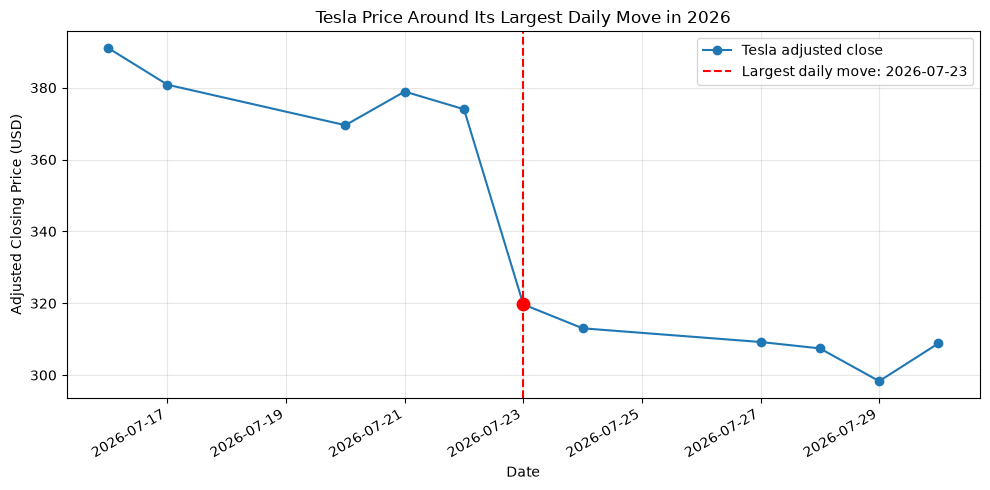

In [9]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(
    event_window.index,
    event_window["Close"],
    marker="o",
    label="Tesla adjusted close"
)
ax.axvline(
    event_date,
    color="red",
    linestyle="--",
    label=f"Largest daily move: {event_date:%Y-%m-%d}"
)
ax.scatter(
    event_date,
    tesla.loc[event_date, "Close"],
    color="red",
    s=80,
    zorder=5
)
ax.set_title("Tesla Price Around Its Largest Daily Move in 2026")
ax.set_xlabel("Date")
ax.set_ylabel("Adjusted Closing Price (USD)")
ax.grid(alpha=0.3)
ax.legend()
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

Figure caption: Tesla's adjusted closing price around its
largest absolute daily return in the study period. The red dashed
line marks July 23, 2026, when the stock fell 14.52% from the
previous trading day's close. Prices continued to decline,
reaching a window low of $298.32 on July 29. This chart shows
the timing and extent of the decline; its possible business
causes require investigation using external sources.

In [10]:
# Average volume over the 20 trading days before the event
previous_20_days = tesla.iloc[
    max(0, event_position - 20):event_position
]
average_volume = previous_20_days["Volume"].mean()
event_volume = tesla.loc[event_date, "Volume"]
volume_ratio = event_volume / average_volume
print("Event date:", event_date.date())
print(f"Event-day volume: {event_volume:,.0f} shares")
print(f"Previous 20-day average: {average_volume:,.0f} shares")
print(f"Volume ratio: {volume_ratio:.2f} times")

Event date: 2026-07-23
Event-day volume: 115,606,400 shares
Previous 20-day average: 38,959,480 shares
Volume ratio: 2.97 times


### Event Analysis: July 23, 2026 — Data Evidence

Tesla's adjusted closing price fell from $374.01 on July 22
to $319.69 on July 23, a daily decline of 14.52%. This was
the largest absolute daily return in our study period.

Trading volume on July 23 was 115,606,400 shares, approximately
2.97 times the average of 38,959,480 shares over the previous
20 trading days. The sharp price decline therefore coincided
with unusually high trading activity.

Within the July 16–30 event window, the highest adjusted closing
price was $391.06 on July 16, and the lowest was $298.32 on
July 29.

These results describe the price movement and trading activity.
External news sources are still needed to investigate possible
business causes, and the data alone cannot establish causation.

### Possible Business Explanation

Tesla released its second-quarter financial results on July 22,
2026, the day before the sharp decline.

Reuters reported that adjusted earnings were $0.33 per share,
below the $0.51 expected by analysts. Capital spending reached
$5.8 billion, and free cash flow was approximately negative
$1.1 billion as Tesla increased investment in AI and robotics.

These results may have increased investor concerns about
profitability and the cost of Tesla's expansion plans. The timing
of the report is consistent with the 14.52% decline on July 23.
Trading volume was also 2.97 times the previous 20-day average,
showing unusually high activity during the sell-off.

However, this evidence does not prove that the earnings report
was the only cause. Broader market conditions and other news
may also have affected the stock.

### Sources

1. Tesla Investor Relations. "Tesla Releases Second Quarter 2026
   Financial Results." July 22, 2026.
   https://ir.tesla.com/press-release/tesla-releases-second-quarter-2026-financial-results

2. Reuters, Akash Sriram and Abhirup Roy. "Tesla profit disappoints,
   EV maker posts cash burn as AI spending surges." July 22, 2026.
   Published through Fidelity.
   https://www.fidelity.com/news/article/company-news/202607221609RTRSNEWSCOMBINED_KBN3TI2I8-OUSBS_1

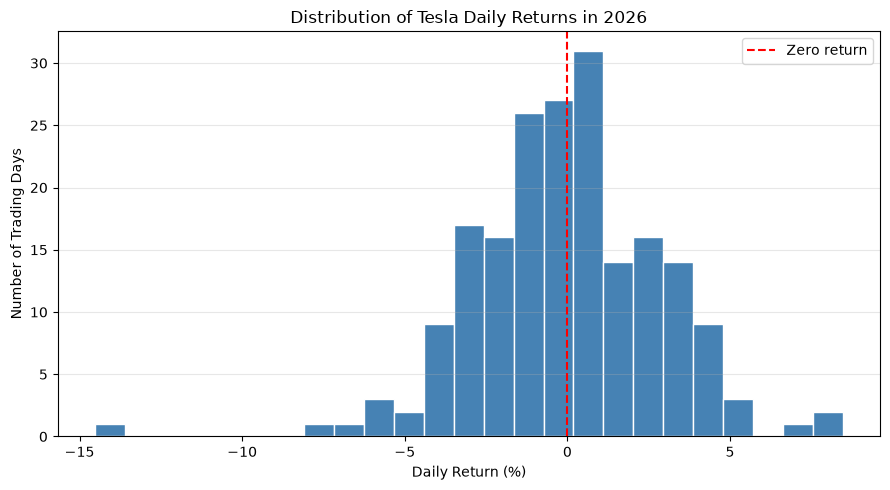

In [11]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(
    tesla["Daily_Return_Pct"].dropna(),
    bins=25,
    color="steelblue",
    edgecolor="white"
)

ax.axvline(0, color="red", linestyle="--", label="Zero return")
ax.set_title("Distribution of Tesla Daily Returns in 2026")
ax.set_xlabel("Daily Return (%)")
ax.set_ylabel("Number of Trading Days")
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

**Figure caption:** Distribution of Tesla's daily percentage
returns during the study period. Each bar shows the number of
trading days within a return interval. The dashed red line marks
zero return. This chart helps distinguish typical daily movements
from unusually large gains or losses. The first observation is
excluded because it has no previous trading day for calculating
a return.

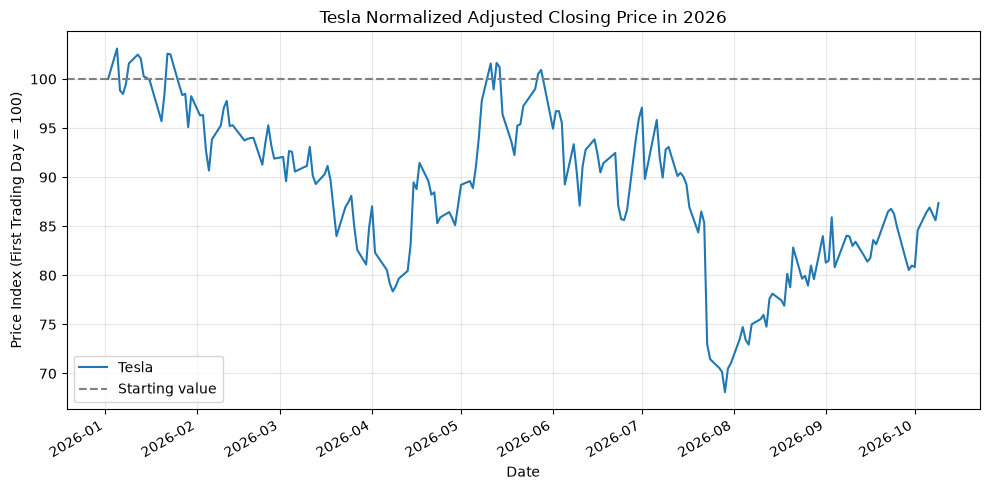

First trading day: 2026-01-02
Last trading day: 2026-10-09
Price change over the study period: -12.64%


In [12]:
normalized_price = tesla["Close"] / tesla["Close"].iloc[0] * 100
period_return = (
    tesla["Close"].iloc[-1] / tesla["Close"].iloc[0] - 1
) * 100
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(tesla.index, normalized_price, label="Tesla")
ax.axhline(100, color="gray", linestyle="--", label="Starting value")
ax.set_title("Tesla Normalized Adjusted Closing Price in 2026")
ax.set_xlabel("Date")
ax.set_ylabel("Price Index (First Trading Day = 100)")
ax.legend()
ax.grid(alpha=0.3)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()
print("First trading day:", tesla.index[0].date())
print("Last trading day:", tesla.index[-1].date())
print(f"Price change over the study period: {period_return:.2f}%")

**Figure caption:** Tesla's adjusted closing price over the full
study period, normalized to 100 on the first trading day.
Values above 100 indicate a price increase relative to the
starting date, while values below 100 indicate a decrease.
Normalization provides a common scale for the later comparison
with BYD and NIO.

### Main Findings

1. Tesla's adjusted closing price decreased by 12.64% from
   January 2 to October 9, 2026. Although the stock recovered
   after its late-July decline, it ended the study period
   below its starting level.

2. Daily returns had a standard deviation of 2.86 percentage
   points. The largest daily decline was 14.52%, while the
   largest daily gain was 8.46%. The most extreme downward
   movement was therefore larger than the most extreme
   upward movement.

3. The July 23 decline coincided with unusually high trading
   volume: 115,606,400 shares, or 2.97 times the previous
   20-trading-day average. This indicates that the sharp
   price movement was accompanied by increased trading activity.

4. Among complete months, January had the highest average
   adjusted closing price at $437.00, while August had the
   lowest at $340.21. October includes only seven trading
   days and should be treated as a partial month.

### Limitations

This analysis covers only part of 2026, so its findings may
not represent Tesla's long-term performance. News timing,
price changes, and trading volume suggest possible explanations
but cannot prove causation. Broader market conditions and
other events may also have influenced the stock.

Comparison with BYD and NIO is still needed to determine
whether Tesla's performance and volatility differed from
those of the other companies.